# QUASTELL demo: background, thermodynamics and QNMs

Every functionality of the `QUASTELL` package, one per cell, on the Bea-Mateos model with `phiM = 1`, `phiQ = 10`, `chi = 1.2`.

The last few cells (q scan, dispersion relation, growth rates) take several minutes each.

### Setup
Activate the project this notebook belongs to (the repository root, one level up). The first time, `Pkg.instantiate()` installs the dependencies.

`Bea_Mateos(phiM, phiQ; chi, nu)` builds V, V', V'' and locates `phiMax`.

In [2]:
using Pkg
Pkg.activate("..")
Pkg.instantiate()

using QUASTELL
using LinearAlgebra, Printf, Plots, ProgressMeter

m = Bea_Mateos(1.0, 10; chi = 1.2)

  Activating project at `c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL`
Precompiling project...
  ✓ QUASTELL
  1 dependency successfully precompiled in 29 seconds (183 already precompiled)


Bea_Mateos(phiM = 1.0, phiQ = 10.0, chi = 1.2, nu = 1.0)
  phiMax = 1.539456   V(phiMax) = -7.14223
  cached backgrounds: 0   thermodynamics: not computed   Tc: -
  QNM runs: 0

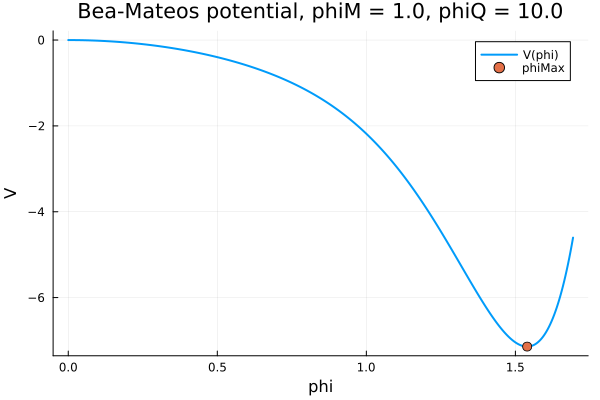

In [3]:
plot_potential(m)

### 1. Background at one phiH
Damped Newton with continuation from pure AdS. Cached by `(N, phiH)`.

In [4]:
bg = background(m, 0.3; N = 40)
@printf("T = %.8g   S = %.8g   Lambda = %.8g   res = %.2e   converged = %s\n",
        bg.T, bg.S, bg.Lambda, bg.res, bg.converged)
@printf("T/Lambda = %.8g   s/Lambda^3 = %.8g\n", bg.T/bg.Lambda, bg.S/bg.Lambda^3)

T = 0.31942632   S = 2.964797   Lambda = 0.35152238   res = 7.29e-11   converged = true
T/Lambda = 0.90869412   s/Lambda^3 = 68.255245


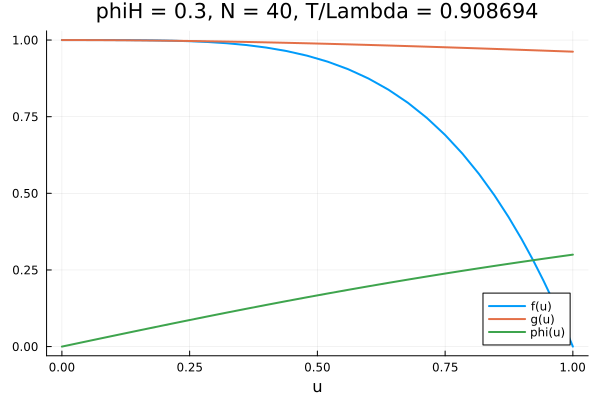

In [5]:
plot_solution(m, bg)

### 2. Full thermodynamics
Sweep phiH up to `phiMax`; failed solves stay `NaN`. `F = -p` with `p` from `dp = s dT` anchored at the coldest point, so it is a free energy up to a constant; `eps = sT - p`.

In [6]:
th = thermodynamics!(m; N = 50, nphi = 2000, progress = true);
@printf("converged %d/%d   Tc = %s\n", count(th.converged), length(th.converged),
        string(m.Tc))
i0 = findfirst(th.converged)
@printf("conformal check at the hot end: eps/(3p) = %.6f   (eps+p)/(sT) = %.8f\n",
        th.e[i0]/(3*th.p[i0]), (th.e[i0]+th.p[i0])/(th.s[i0]*th.t[i0]))

thermodynamics: 100%|███████████████████████████████████| Time: 0:01:53


converged 2000/2000   Tc = 0.37356749557573704
conformal check at the hot end: eps/(3p) = 1.000749   (eps+p)/(sT) = 1.00000000


┌ Info: critical temperature
│   Tc = 0.37356749557573704
└ @ QUASTELL c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL\src\thermodynamics.jl:65


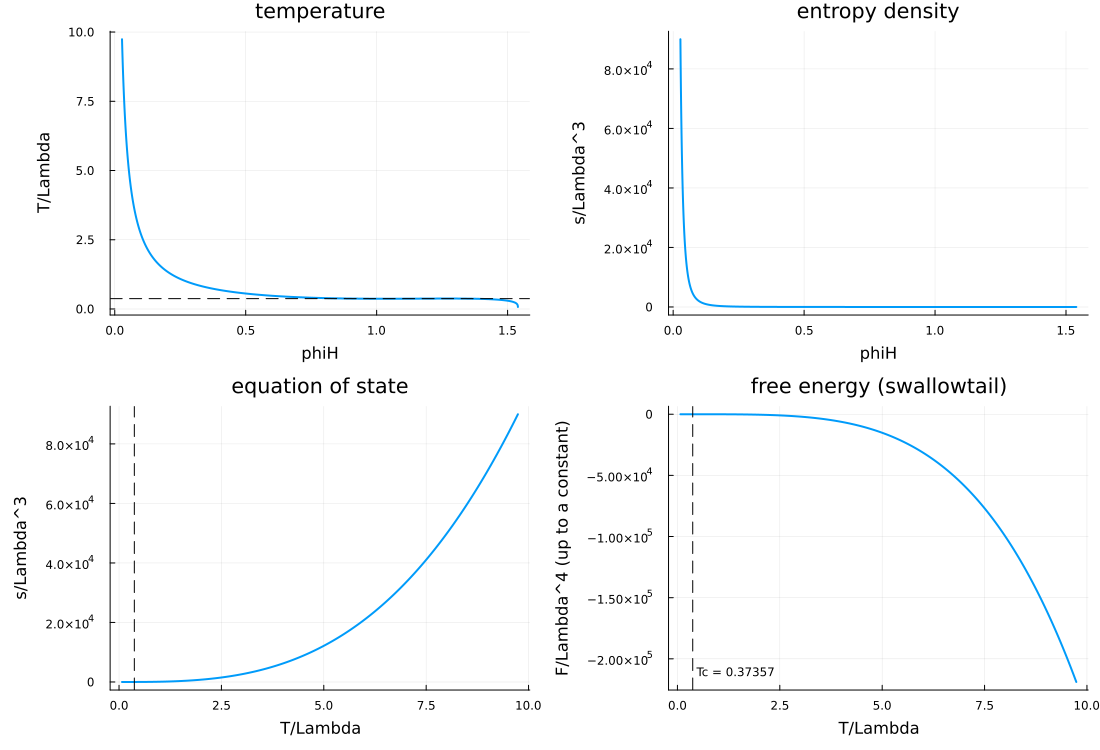

In [7]:
plot_thermodynamics(m)

`zoom = w` restricts the T axis to `Tc*(1 +- w)`; the three branches of `F` cross at `Tc`.

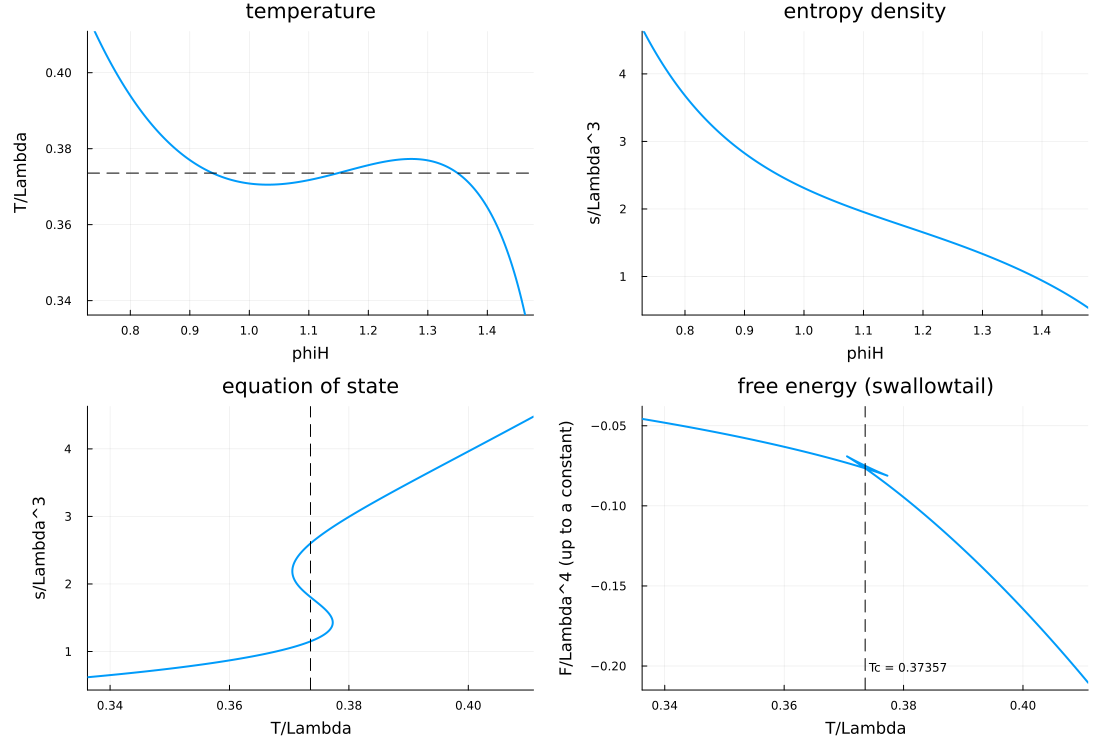

In [9]:
plot_thermodynamics(m; zoom = 0.1)

### 3. The fluctuation matrices
`M(w) = Mt[1] + w Mt[2] + w^2 Mt[3] + w^3 Mt[4]`; `M0, M1` are the companion form.

Two steps happen first. `rescale_fields!` substitutes `Zphi = u^2 Ztilde`: the normalizable branch is `u^3` and the discarded one `u^1`, so without this both are ordinary polynomials, nothing excludes the sourced solution, and the entire Zphi tower is missing. Then `boundary_rows!` fills rows 1, N+1 and N, which the bulk equations leave empty.

In [10]:
M0, M1, Mt, b = mtildes(m, 0.3; q = 0.3, N = 40);
@printf("%d blocks of %s   companion %s\n", length(Mt), string(size(Mt[1])),
        string(size(M0)))
w = 1.234 + 0.567im
M = Mt[1] + w*Mt[2] + w^2*Mt[3] + w^3*Mt[4]
@printf("rank M(w) = %d of %d   (must be full, else det = 0 identically)\n",
        rank(M), size(M, 1))

4 blocks of (80, 80)   companion (240, 240)
rank M(w) = 79 of 80   (must be full, else det = 0 identically)


Without the boundary rows, two rows are identically zero and the pencil is singular:

In [ ]:
_, _, Mt0, _ = mtildes(m, 0.3; q = 0.3, N = 40, bc = false);
Mraw = Mt0[1] + w*Mt0[2] + w^2*Mt0[3] + w^3*Mt0[4]
@printf("rank without bc = %d of %d\n", rank(Mraw), size(Mraw, 1))
@printf("|row 40| = %.2e   |row 41| = %.2e   typical row = %.2e\n",
        norm(Mraw[40, :]), norm(Mraw[41, :]), norm(Mraw[20, :]))

And without the rescaling the Zphi tower disappears while everything else is untouched -- compare the two lists:

In [ ]:
for rs in ((0, 0), (2, 0))
    rr = qnms(m, 1e-3; q = 0.05, Ns = (60, 90), rtol = 1e-2, cutoff = 40.0,
              verbose = false, rescale = rs)
    p = sort(filter(z -> real(z) > 1e-6, rr.lambda), by = z -> -imag(z))
    @printf("rescale = %-7s : %s\n", string(rs),
            join([@sprintf("%.4f%+.4fi", real(z), imag(z)) for z in p], "  "))
end

The export also carries a spurious overall factor of `f` in equation 1, which kills its row at the horizon; `boundary_rows!` then has to impose the derivation's ingoing condition, whose derivative part factors as `(f'(1)sqrt(g(1)) + 4 i pi T lambda)(...)` with `f'(1)sqrt(g(1)) = -4 pi T` identically -- so it vanishes at `lambda = -i` and parks a spurious mode there, for every background and momentum.

`divide_f = true` (the default) divides the factor out instead, at the level of the coefficient functions of `a Z'' + b Z' + c Z`, taking the horizon value from the limit `ahat(1) = a'(1)/f'(1)`. Neither cheaper route works: the division cannot be done symbolically, because with `f, g, phi, V` as free symbols the `omega^0` `Z2` coefficient does not vanish at `u = 1` (its vanishing is on-shell), so `Cancel` would need the background equations of motion the master equations were already derived with; and it cannot be done by a row operation either, because the `u = 1` row is identically zero, so any combination of rows already lies in the row space and the rank cannot change.

Read the rank *after* row balancing. Before balancing it reads one short, but the near-null direction is equation 2 at the second gridpoint, whose row norm is ~1e-9 of the largest because of *its* own overall factor of `u` -- nothing to do with the `f` division. `_spectrum` balances, so the pencil handed to `eigvals` is nonsingular.

**`rtol` matters here.** The divided pencil is worse conditioned (cond ~1e12 at N = 90 against ~2e5), so eigenvalues carry an error of order 1e-4 and a nearly-real mode can have its imaginary part smeared onto the wrong side of zero. At `phiH = 0.3, q = 0.3` -- `T/Lambda = 0.905`, far above `Tc`, so certainly stable -- a spurious pair at `+-0.339 + 9e-5i` survives a three-grid filter at `rtol = 1e-3` or looser, and is rejected at the default `rtol = 1e-4`. So read stability only at `rtol <= 1e-4`. Loosening to `1e-3` buys the deepest `Z2` overtone but costs that guarantee; the dispersion and growth-rate cells below stay at `1e-2` deliberately, because they track one branch by position rather than by the sign of `Im lambda`.

In [ ]:
function ranks(m, phiH, q, N, df)
    _, _, Mt, b = mtildes(m, phiH; q = q, N = N, divide_f = df)
    sc = 2pi*b.T
    A  = [ComplexF64.(Mt[n]) .* sc^(n-1) for n in eachindex(Mt)]
    for i in axes(A[1], 1)                      # row balancing, as in _spectrum
        s = maximum(maximum(abs, view(X, i, :)) for X in A)
        s > 0 && for X in A; @views X[i, :] ./= s; end
    end
    wg = 1.234+0.567im
    Mr = Mt[1] + wg*Mt[2] + wg^2*Mt[3] + wg^3*Mt[4]
    Mb = A[1]  + wg*A[2]  + wg^2*A[3]  + wg^3*A[4]
    return rank(Mr), rank(Mb), size(Mb, 1)
end

for df in (false, true)
    rr = qnms(m, 1e-3; q = 0.05, Ns = (50, 70, 90), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df)
    pim = filter(z -> abs(real(z)) < 1e-6 && abs(z) < 6, rr.lambda)
    r0, r1, nn = ranks(m, 1e-3, 0.05, 60, df)
    @printf("divide_f = %-5s : rank %d/%d raw, %d/%d balanced , lambda = -i %s\n",
            df, r0, nn, r1, nn, isempty(pim) ? "absent" : "PRESENT")
    for z in sort(filter(z -> real(z) > 1e-6, rr.lambda), by = z -> -imag(z))
        @printf("      %+.9f %+.9f i\n", real(z), imag(z))
    end
end

# The factor is not cosmetic: at the spinodal point the hand-imposed horizon row
# suppresses the physical instability and reports lambda = -i in its place.
println()
for df in (false, true)
    rs = qnms(m, 1.3126; q = 0.1, Ns = (50, 70, 90), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df)
    up = filter(z -> imag(z) > 1e-8, rs.lambda)
    @printf("phiH = 1.3126 (spinodal) , q = 0.1  , divide_f = %-5s : %d unstable %s\n",
            df, length(up), join([@sprintf("%+.6fi", imag(z)) for z in up], " "))
end
for df in (false, true)
    rs = qnms(m, 0.3; q = 0.3, Ns = (50, 70, 90), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df)
    @printf("phiH = 0.3 (T/Lambda = 0.905, stable) , q = 0.3 , divide_f = %-5s : %d with Im > 0\n",
            df, count(z -> imag(z) > 1e-8, rs.lambda))
end

### 4. The singular band
The second-derivative coefficient vanishes at `w^2 = a(u)`. Collocation puts one nearly-real pair per grid point there; those are artifacts and `qnms` drops them.

In [ ]:
lo, hi = singular_band(m, b, 0.3, b.T)
@printf("band |w/2piT| in [%.6f, %.6f]   ->   |lambda|/q in [%.4f, %.4f]\n",
        lo, hi, lo/0.3, hi/0.3)

### 5. Quasinormal modes
Spectrum recomputed on every grid in `Ns` (background re-solved, never interpolated); only modes present on all of them survive. `progress = true` shows a bar over the grids, and `dispersion` / `growth_rate` show one over the momenta by default.

In [ ]:
r = qnms(m, 1.5; q = 0.0, Ns = (90, 100, 110), rtol = 1e-4, cutoff = 40.0,
         progress = true, divide_f = true)
show_modes(r)

In [ ]:
plot_qnms(r)

In [ ]:
plot_convergence(r)

In [ ]:
# All modes as a function of q.  Faint grey is the raw spectrum of each grid, black
# the modes that converge across all of them.  On top of that, the purely imaginary
# modes are followed in q and drawn in colour: a complex-conjugate pair collides on
# the imaginary axis and divides into two purely imaginary modes, one of which then
# becomes unstable.  Seeded at the first q that HAS an on-axis mode -- at very small
# q there are none, so seeding at the first momentum finds nothing.
phiH_scan = 1.5
qs_scan   = 1e-3:0.1:10.0
bscan     = background(m, phiH_scan; N = 90)

qraw = Float64[]; lraw = ComplexF64[]
byq  = Vector{Vector{ComplexF64}}()
bar  = Progress(length(qs_scan); desc = "q scan: ")
for q in qs_scan
    r = qnms(m, phiH_scan; q = q, Ns = (90, 100), rtol = 1e-4, cutoff = 20.0,
             verbose = false, progress = false)
    sc = 2pi * r.T
    for w in r.raw                                  # pooled over the three grids
        append!(qraw, fill(q, length(w))); append!(lraw, w ./ sc)
    end
    push!(byq, sort(r.lambda, by = z -> -imag(z)))
    QUASTELL._tick!(bar, [(:q, q), (:converged, length(r.lambda))])
end
qcon = vcat([fill(q, length(byq[i])) for (i, q) in enumerate(qs_scan)]...)
lcon = vcat(byq...)
@printf("phiH = %.4f   T/Lambda = %.5f   %d raw / %d converged over %d momenta\n",
        phiH_scan, bscan.T/bscan.Lambda, length(lraw), length(lcon), length(qs_scan))

# --- follow the purely imaginary modes ---------------------------------------
axtol  = 1e-4      # |Re lambda| below this counts as "on the axis"
ntrack = 4         # how many to follow from the seed, least damped first
gate   = 0.5       # abandon a branch if the nearest mode is further than this
qv     = collect(qs_scan)
i0     = findfirst(i -> any(z -> abs(real(z)) < axtol, byq[i]), eachindex(byq))
tracks = Vector{Vector{ComplexF64}}(); tq = Vector{Vector{Float64}}()
if i0 === nothing
    println("no mode on the imaginary axis at any q -- nothing to track")
else
    seed = filter(z -> abs(real(z)) < axtol, byq[i0])
    seed = seed[1:min(ntrack, length(seed))]
    tracks = [ComplexF64[z] for z in seed]
    tq     = [Float64[qv[i0]] for _ in seed]
    for i in (i0+1):length(qv)
        cand = copy(byq[i])
        for (b, tr) in enumerate(tracks)
            isempty(cand) && continue
            prev = tr[end]
            pred = length(tr) >= 2 ? prev + (prev - tr[end-1]) : prev   # linear in q
            k = argmin(abs.(cand .- pred))
            abs(cand[k] - pred) > gate && continue                      # branch lost
            push!(tr, cand[k]); push!(tq[b], qv[i]); deleteat!(cand, k)
        end
    end
    @printf("seeded %d track(s) at q = %.3f\n", length(tracks), qv[i0])
    for (b, tr) in enumerate(tracks)
        off = findfirst(z -> abs(real(z)) > axtol, tr)
        up  = findall(z -> imag(z) > 1e-8, tr)
        @printf("  track %d: %2d pts, Im %+.5f -> %+.5f, unstable for q <= %s, leaves the axis %s\n",
                b, length(tr), imag(tr[1]), imag(tr[end]),
                isempty(up) ? "never" : @sprintf("%.3f", tq[b][up[end]]),
                off === nothing ? "never" : @sprintf("at q = %.3f", tq[b][off]))
    end
end

p_re = scatter(qraw, real.(lraw); ms = 2, msw = 0, alpha = 0.25, c = :gray,
               label = "raw", xlabel = "q", ylabel = "Re w/2piT")
scatter!(p_re, qcon, real.(lcon); ms = 4, msw = 0, c = :black,
         label = "converged ($(length(lcon)))")
p_im = scatter(qraw, imag.(lraw); ms = 2, msw = 0, alpha = 0.25, c = :gray,
               label = "raw", xlabel = "q", ylabel = "Im w/2piT")
scatter!(p_im, qcon, imag.(lcon); ms = 4, msw = 0, c = :black,
         label = "converged ($(length(lcon)))")
hline!(p_im, [0.0]; ls = :dash, c = :gray, label = "")

cols = [:red, :dodgerblue, :seagreen, :orange]
for (b, tr) in enumerate(tracks)
    c = cols[mod1(b, length(cols))]
    plot!(p_re, tq[b], real.(tr); c = c, lw = 2, m = :circle, ms = 5, msw = 0,
          label = "track $b")
    plot!(p_im, tq[b], imag.(tr); c = c, lw = 2, m = :circle, ms = 5, msw = 0,
          label = "track $b")
end
plot(p_re, p_im; layout = (1, 2), size = (1050, 430), legend = :best,
     left_margin = 6Plots.mm, bottom_margin = 5Plots.mm)

### 6. Validation: AdS brane limit
At `phiH -> 0` the channels decouple and each must reproduce its AdS5-Schwarzschild tower: Z2 the `Delta = 4` one, Zphi the `Delta = 3` one (the bulk scalar has `m^2 = V''(0) = -3`). The sound mode must go to `+-q/sqrt(3) - i q^2/3`.

In [ ]:
tree = [1.559725796-1.373337872im, 2.584760-2.381785im, 3.594-3.385im]  # Delta = 4
scal = [1.099407283-0.879767314im, 2.105948627-1.887444155im,
        3.107718-2.888602im]                              # Delta = 3
q = 0.05*0
rv = qnms(m, 1e-3; q = q, Ns = (60, 70 , 90), rtol = 1e-4, cutoff = 40.0, verbose = false,
            progress = true)
pos = sort(filter(z -> real(z) > 1e-6, rv.lambda), by = z -> -imag(z))
e1 = q/sqrt(3) - im*q^2/3
@printf("%-28s %-28s %-9s %s\n", "computed", "expected", "|diff|", "")
for z in pos
    j = findfirst(t -> abs(z-t) < 0.03, tree)
    k = findfirst(t -> abs(z-t) < 0.03, scal)
    ref = j !== nothing ? tree[j] : k !== nothing ? scal[k] :
          abs(z-e1) < 0.01 ? e1 : NaN+NaN*im
    lbl = j !== nothing ? "Z2   n=$j" : k !== nothing ? "Zphi n=$k" :
          abs(z-e1) < 0.01 ? "sound" : "?"
    @printf("%+.9f%+.9fi   %+.9f%+.9fi   %-9.1e %s\n",
            real(z), imag(z), real(ref), imag(ref), abs(z-ref), lbl)
end

The Christmas tree: two towers plus the hydrodynamic mode at the origin.

In [ ]:
pt = scatter(vcat(real.(tree), -real.(tree)), vcat(imag.(tree), imag.(tree)),
             ms = 11, mc = :transparent, msc = :red, msw = 2,
             label = "AdS5 Delta=4 (q=0)", legend = :bottomleft,
             xlabel = "Re w/2piT", ylabel = "Im w/2piT",
             size = (680, 640), xlims = (-4.2, 4.2), ylims = (-4, 0.3))
scatter!(pt, vcat(real.(scal), -real.(scal)), vcat(imag.(scal), imag.(scal)),
         ms = 11, mc = :transparent, msc = :blue, msw = 2,
         label = "AdS5 Delta=3 (q=0)")
hline!(pt, [0.0], ls = :dash, c = :gray, label = "")
scatter!(pt, real.(rv.lambda), imag.(rv.lambda), ms = 6, c = :black, msw = 0,
         label = "computed, phiH = 1e-3, q = 0.05")

### 7. Dispersion relation
Branches are tracked in q by continuation after folding the `+-Re` symmetry, so `dRe(lambda)/dq` at small q *is* the speed of sound; `sound_speed` fits `Re lambda = cs q + b q^3`.

In [ ]:
d = dispersion(m, 1e-4; qs = 0.05:0.05:8.0, nmodes = 2, Ns = (50, 70, 90),
               rtol = 1e-2, cutoff = 40.0);
cs, res = sound_speed(d; nmax = 2)
@printf("cs = %.9f   cs^2 = %.9f   (conformal: %.9f, 1/3)   residual %.1e\n",
        cs, cs^2, 1/sqrt(3), res)
plot_dispersion(d)

### 8. Instability on the spinodal branch
Where `ds/dT < 0` the sound mode turns purely imaginary and one root crosses to `Im > 0`. Nothing is filtered on stability; `plot_qnms` marks unstable modes with a red star.

In [ ]:
r2 = qnms(m, 1.3126; q = 0.0, Ns = (50, 70, 90), rtol = 1e-4, cutoff = 40.0)
show_modes(r2; nmax = 6)

In [ ]:
plot_qnms(r2; showraw = false)

### 9. Growth rate, checked against the equation of state
In the spinodal region `cs^2 < 0`, so `gamma = Im omega = |cs| k - Gamma k^2/2`: an inverted parabola vanishing at `k = 2|cs|/Gamma`. Its slope at the origin must agree with `cs^2 = dp/de = (s/T)/(ds/dT)` taken straight from the thermodynamics, which never enters the QNM computation.

In [ ]:
phiH = 1.3126
ok = findall(th.converged); i = ok[argmin(abs.(th.phiH[ok] .- phiH))]
for h in (2, 5)
    dsdT = (th.s[i+h] - th.s[i-h]) / (th.t[i+h] - th.t[i-h])
    cs2  = (th.s[i]/th.t[i]) / dsdT
    @printf("thermodynamics, stencil +-%d : ds/dT = %+.5f  cs^2 = %+.5f  |cs| = %.5f\n",
            h, dsdT, cs2, sqrt(abs(cs2)))
end
g = growth_rate(m, phiH; qs = 0.005:0.005:0.03, Ns = (50, 70), rtol = 1e-2,
                cutoff = 40.0, nfit = 3, progress = false)
@printf("QNM growth rate            : |cs| = %.5f\n", g.cs)

In [ ]:
g2 = growth_rate(m, 1.3126; qs = 0.05:0.1:1.25, Ns = (50, 70, 90), rtol = 1e-2,
                 cutoff = 40.0)
@printf("T/Lambda = %.5f   |cs| = %.5f   Gamma = %.5f   k_max/Lambda = %.4f\n",
        g2.TL, g2.cs, g2.Gamma, g2.kmax)
@printf("%9s %14s %14s\n", "k/Lambda", "gamma/Lambda", "hydro (2.16)")
for i in eachindex(g2.kL)
    g2.gL[i] < -0.5 && break
    @printf("%9.4f %14.7f %14.7f\n", g2.kL[i], g2.gL[i],
            g2.cs*g2.kL[i] - 0.5*g2.Gamma*g2.kL[i]^2)
end

In [ ]:
plot_growth_rates(m, (1.15, 1.25, 1.3126, 1.40); qs = 0.05:0.1:1.35,
                  Ns = (80, 90, 100), rtol = 1e-3, cutoff = 40.0)

### 10. Cached state
`m` accumulates everything computed so far.

In [ ]:
m